In [3]:
import numpy as np
import pandas as pd
import yfinance as yf
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [4]:
tickers = ["AAPL", "GOOGL", "AMZN", "TSLA", "META","MSFT"]

data_list = []
for ticker in tickers:
    df = yf.download(ticker, start="2010-01-01", end="2025-03-03")[["Close"]]
    df.columns = [ticker]
    data_list.append(df)

df_all = pd.concat(data_list, axis=1).dropna()

YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [5]:

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(df_all)

def create_sequences(data, time_steps=60):
    X, y = [], []
    for i in range(len(data) - time_steps):
        X.append(data[i:i + time_steps])
        y.append(data[i + time_steps])
    return np.array(X), np.array(y)

time_steps = 120
X, y = create_sequences(scaled_data, time_steps)

In [6]:
split = int(len(X) * 0.85)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

In [7]:
model = Sequential([
    LSTM(50, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2),
    LSTM(50, return_sequences=False),
    Dropout(0.2),
    Dense(25),
    Dense(y_train.shape[1])
])
model.compile(optimizer='adam', loss='mean_squared_error')
model.fit(X_train, y_train, batch_size=50, epochs=20, validation_data=(X_test, y_test))

c:\Users\Lakshin Khurana\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 8s 96ms/step - loss: 0.0261 - val_loss: 0.0188
Epoch 2/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 7s 124ms/step - loss: 0.0031 - val_loss: 0.0187
Epoch 3/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 70ms/step - loss: 0.0023 - val_loss: 0.0120
Epoch 4/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 71ms/step - loss: 0.0017 - val_loss: 0.0097
Epoch 5/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 75ms/step - loss: 0.0017 - val_loss: 0.0069
Epoch 6/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 67ms/step - loss: 0.0014 - val_loss: 0.0065
Epoch 7/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 69ms/step - loss: 0.0014 - val_loss: 0.0068
Epoch 8/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 71ms/step - loss: 0.0011 - val_loss: 0.0060
Epoch 9/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 70ms/step - loss: 0.0011 - val_loss: 0.0042
Epoch 10/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 68ms/step - loss: 0.0011 - val_loss: 0.0036
Epoch 11/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 66ms/step - loss: 9.8195e-04 - val_loss: 0.0040
Epoch 12/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 74ms/step - loss

In [8]:
train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)

train_predictions = scaler.inverse_transform(train_predictions)
test_predictions = scaler.inverse_transform(test_predictions)
y_test_actual = scaler.inverse_transform(y_test)

83/83 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


In [11]:
mse = mean_squared_error(y_test_actual, test_predictions)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_actual, test_predictions)
r2 = r2_score(y_test_actual, test_predictions)

print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"R² Score: {r2:.2f}")

Mean Squared Error (MSE): 889.38
Root Mean Squared Error (RMSE): 29.82
Mean Absolute Error (MAE): 18.80
R² Score: 0.78


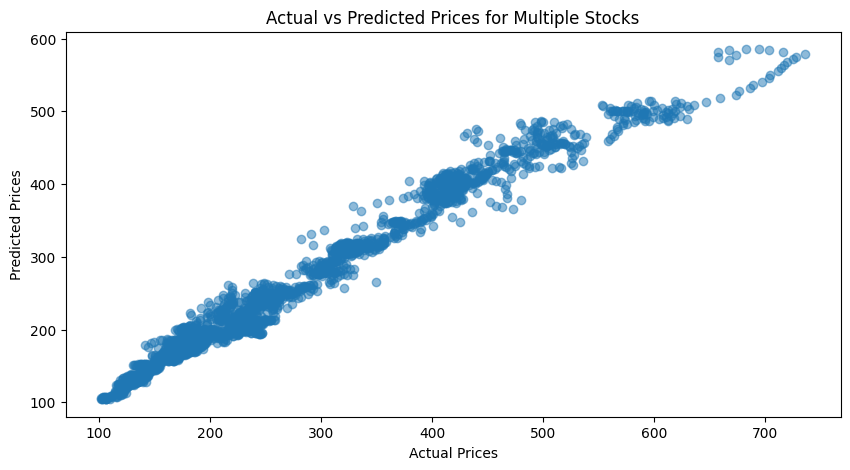

In [12]:
plt.figure(figsize=(10, 5))
plt.scatter(y_test_actual.flatten(), test_predictions.flatten(), alpha=0.5)
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted Prices for Multiple Stocks")
plt.show()

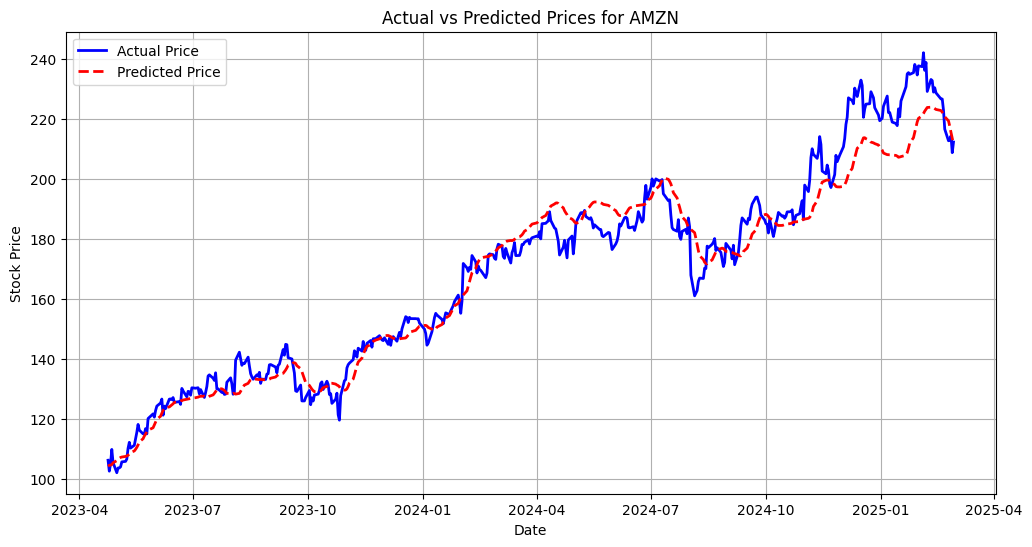

In [17]:
stock_index = 2 #["AAPL", "GOOGL", "AMZN", "TSLA", "META", "MSFT"]
actual_prices = y_test_actual[:, stock_index]
predicted_prices = test_predictions[:, stock_index]

dates = df_all.index[-len(y_test_actual):]
plt.figure(figsize=(12, 6))
plt.plot(dates, actual_prices, label="Actual Price", color='blue', linewidth=2)
plt.plot(dates, predicted_prices, label="Predicted Price", color='red', linestyle='dashed', linewidth=2)
plt.xlabel("Date")
plt.ylabel("Stock Price")
plt.title(f"Actual vs Predicted Prices for {tickers[stock_index]}")
plt.legend()
plt.grid()
plt.show()

In [16]:
# def predict_future_prices(model, df, scaler, days=180, time_steps=60):
#     num_features_expected = scaler.scale_.shape[0]
#     if df.shape[1] != num_features_expected:
#         raise ValueError(f"DataFrame has {df.shape[1]} features but scaler expects {num_features_expected}. "
#                          "Please pass the same feature set used during training.")

#     last_sequence = df.iloc[-time_steps:].values
#     current_sequence = scaler.transform(last_sequence)
#     future_predictions = []
#     close_index = num_features_expected - 1
#     close_min = scaler.min_[close_index]
#     close_scale = scaler.scale_[close_index]

#     for _ in range(days):
#         X_input = current_sequence.reshape(1, time_steps, num_features_expected)
#         predicted_scaled = model.predict(X_input)[0, 0]
#         new_row = current_sequence[-1].copy()
#         new_row[close_index] = predicted_scaled
#         predicted_original = predicted_scaled / close_scale + close_min
#         future_predictions.append(predicted_original)
#         current_sequence = np.vstack([current_sequence[1:], new_row])


#     future_dates = pd.date_range(start=df.index[-1], periods=days+1, freq='B')[1:]
#     future_df = pd.DataFrame({'Date': future_dates, 'Predicted Price': future_predictions})
#     future_df.set_index('Date', inplace=True)
#     future_df
#     return future_df

# def plot_future_predictions(df, future_df, stock_ticker):
#     plt.figure(figsize=(12, 5))

#     if df.shape[1] > 1 and 'Close' in df.columns:
#         actual = df['Close']
#     else:
#         actual = df.iloc[:, 0]

#     plt.plot(df.index[-100:], actual.iloc[-100:], label="Actual Price", color="blue")
#     plt.plot(future_df.index, future_df["Predicted Price"], linestyle="dashed", color="red", label="Predicted Price")
#     plt.xlabel("Date")
#     plt.ylabel("Stock Price (USD)")
#     plt.title(f"Predicted Stock Prices for {stock_ticker} (Next 6 Months)")
#     plt.legend()
#     plt.grid(True)
#     plt.show()


# future_prices = predict_future_prices(model, df_all, scaler, 50, 200)
# plot_future_predictions(df_all, future_prices, "AAPL")
# print(future_prices)
